# Câu d. Data Preparation

Đầu vào: `data/processed/customers_preprocessed.csv` (kết quả câu c, thang đo gốc). Đầu ra: `data/processed/customers_prepared.csv` sẵn sàng cho K-Means ở câu e.

**Không dùng `true_segment`** ở bất kỳ bước nào (chọn thuộc tính, scaler, PCA, phương án). File đầu vào không chứa cột này.

In [1]:
import sys, warnings
sys.path.append("../src")
from utils import *
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)
sns.set_theme(style="whitegrid", font_scale=0.9)
OUT_FIG = ROOT / "outputs" / "figures"; OUT_TAB = ROOT / "outputs" / "tables"
OUT_FIG.mkdir(parents=True, exist_ok=True); OUT_TAB.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED / "customers_preprocessed.csv")
assert LABEL_COL not in df.columns, "Khong duoc co true_segment trong buoc chuan bi"
assert df[INPUT_COLS].isna().sum().sum() == 0
print(df.shape)

(220, 17)


## D1. Biến đổi log1p

Áp dụng cho 6 thuộc tính lệch phải, không âm: `annual_income`, `avg_order_value`, `orders_per_year`, `sessions_per_month`, `tenure_months`, `days_since_last_purchase`. Không log `age` (gần đối xứng) và hai cột tỷ lệ (bị chặn trong [0, 1]).

So dong co gia tri vuot nguong 1,5 x IQR: truoc = 63 | sau = 18


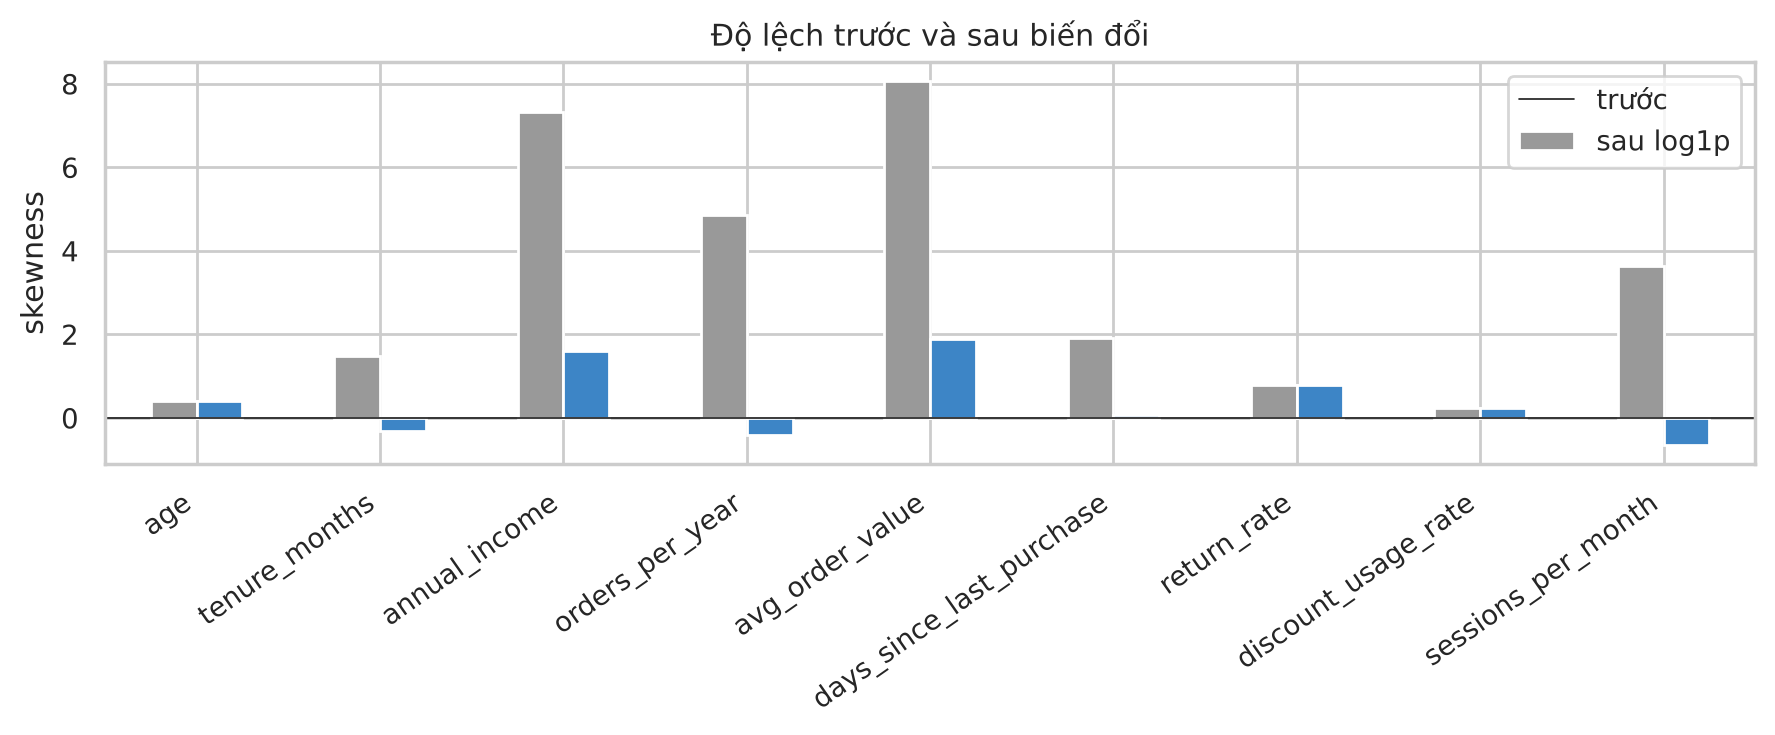

,skew_truoc,skew_sau,bien_doi
age,0.42,0.42,giữ nguyên
tenure_months,1.49,-0.31,log1p
annual_income,7.32,1.60,log1p
orders_per_year,4.86,-0.42,log1p
avg_order_value,8.08,1.90,log1p
days_since_last_purchase,1.93,0.08,log1p
return_rate,0.80,0.80,giữ nguyên
discount_usage_rate,0.23,0.23,giữ nguyên
sessions_per_month,3.64,-0.66,log1p


In [2]:
LOGC = ["annual_income", "avg_order_value", "orders_per_year", "sessions_per_month",
        "tenure_months", "days_since_last_purchase"]
X = df[NUM_COLS].astype(float).copy()
skew_before = X.skew()
for c in LOGC:
    X[c] = np.log1p(X[c])
X = X.rename(columns={c: f"log_{c}" for c in LOGC})
skew = pd.DataFrame({"skew_truoc": skew_before.values, "skew_sau": X.skew().values,
                     "bien_doi": ["log1p" if c in LOGC else "giữ nguyên" for c in NUM_COLS]}, index=NUM_COLS)
iqr_out = lambda d: int(iqr_flags(d, list(d.columns)).any(axis=1).sum())
print("So dong co gia tri vuot nguong 1,5 x IQR: truoc =", iqr_out(df[NUM_COLS].astype(float)), "| sau =", iqr_out(X))

fig, ax = plt.subplots(figsize=(9, 3.8))
skew[["skew_truoc", "skew_sau"]].plot.bar(ax=ax, color=["#999999", "#3d85c6"])
ax.axhline(0, color="k", lw=.6); ax.set_ylabel("skewness"); ax.legend(["trước", "sau log1p"])
ax.set_title("Độ lệch trước và sau biến đổi"); plt.xticks(rotation=35, ha="right"); fig.tight_layout()
fig.savefig(OUT_FIG / "d_skew_before_after.png", dpi=150); plt.show()
skew.round(2)

**Nhận xét D1.** log1p đưa |skewness| của 4/6 cột về dưới 0,7 (orders 4,86 → −0,42; sessions 3,64 → −0,66; tenure 1,49 → −0,31; recency 1,93 → 0,08). income và AOV còn lệch (1,60 và 1,90) vì các khách cực trị hợp lý vẫn nằm xa, nhưng đã giảm từ 7,3 và 8,1. Số dòng có giá trị vượt ngưỡng 1,5 × IQR giảm từ 63 xuống 18. **Lý do dùng log1p:** K-Means tối thiểu tổng bình phương khoảng cách Euclid nên rất nhạy với giá trị cực trị; log nén đuôi phải mà **không xóa** khách giá trị cao (đã quyết định giữ ở câu c), đồng thời biến chênh lệch tuyệt đối thành chênh lệch tương đối, hợp với dữ liệu chi tiêu (khác biệt 200 và 400 quan trọng như 2.000 và 4.000).

## D2–D3. Mã hóa và loại bỏ thuộc tính

- `gender`: 0/1. `region`, `preferred_category`: one-hot (giữ 0/1, không chuẩn hóa).
- Bỏ `membership_tier`: được suy ra từ tổng chi tiêu nên trùng thông tin với `orders_per_year` và `avg_order_value`.
- `sessions_per_month`: bỏ nếu Spearman với `orders_per_year` vượt 0,85.

In [3]:
tier_code = df.membership_tier.map({t: i for i, t in enumerate(ORDINAL_COLS["membership_tier"])})
spend = df.orders_per_year * df.avg_order_value
r_tier = tier_code.corr(spend, method="spearman")
r_sess = df.sessions_per_month.corr(df.orders_per_year, method="spearman")
print(f"Spearman(tier, orders x AOV) = {r_tier:.3f} -> bo membership_tier")
drop_sessions = r_sess > 0.85
print(f"Spearman(sessions, orders) = {r_sess:.3f} -> {'bo' if drop_sessions else 'giu'} sessions_per_month")
if drop_sessions: X = X.drop(columns="log_sessions_per_month")
NUM_FEATS = list(X.columns)

gender = (df.gender == "Nam").astype(int).rename("gender_nam")
region = pd.get_dummies(df.region, prefix="region").astype(int)
category = pd.get_dummies(df.preferred_category, prefix="cat").astype(int)
sp = X.corr("spearman"); iu = np.triu_indices(len(sp), 1)
print("Cap thuoc tinh so con lai co |Spearman| lon nhat:",
      sorted(zip(np.abs(sp.values[iu]).round(2), [f"{sp.index[i]} ~ {sp.columns[j]}" for i, j in zip(*iu)]), reverse=True)[:3])

Spearman(tier, orders x AOV) = 0.883 -> bo membership_tier
Spearman(sessions, orders) = 0.896 -> bo sessions_per_month
Cap thuoc tinh so con lai co |Spearman| lon nhat: [(np.float64(0.76), 'log_annual_income ~ log_avg_order_value'), (np.float64(0.66), 'log_orders_per_year ~ log_days_since_last_purchase'), (np.float64(0.63), 'log_avg_order_value ~ discount_usage_rate')]


## D4. Chuẩn hóa

StandardScaler cho các thuộc tính số (sau log, dữ liệu không còn cực trị nặng nên trung bình và độ lệch chuẩn đáng tin). So sánh nhanh với RobustScaler qua độ lệch chuẩn sau chuẩn hóa: nếu RobustScaler cho các cột có độ lệch chuẩn khác nhau nhiều thì các cột sẽ không cùng trọng số trong khoảng cách Euclid.

In [4]:
scaler = StandardScaler().fit(X)
Xs = pd.DataFrame(scaler.transform(X), columns=NUM_FEATS, index=df.index)
Xr = pd.DataFrame(RobustScaler().fit_transform(X), columns=NUM_FEATS)
raw = df[[c.replace("log_", "") for c in NUM_FEATS]].astype(float)
scale_tab = pd.DataFrame({"std_goc": raw.std().values, "std_sau_log": X.std().values,
                          "std_Standard": Xs.std().values, "std_Robust": Xr.std().values,
                          "max|z|_Standard": Xs.abs().max().values}, index=NUM_FEATS)
print(f"Ti le std lon nhat / nho nhat: goc = {raw.std().max() / raw.std().min():.0f} lan | "
      f"Standard = 1,0 | Robust = {Xr.std().max() / Xr.std().min():.2f} lan")
scale_tab.round(3)

Ti le std lon nhat / nho nhat: goc = 47908 lan | Standard = 1,0 | Robust = 1.77 lan


,std_goc,std_sau_log,std_Standard,std_Robust,max|z|_Standard
age,8.570,8.570,1.002,0.647,3.282
log_tenure_months,32.439,1.134,1.002,0.624,2.009
log_annual_income,510.391,0.633,1.002,0.838,4.832
log_orders_per_year,40.440,1.131,1.002,0.732,2.573
log_avg_order_value,3902.756,0.895,1.002,0.998,4.864
log_days_since_last_purchase,94.931,1.635,1.002,0.626,1.861
return_rate,0.081,0.081,1.002,0.723,3.023
discount_usage_rate,0.230,0.230,1.002,0.564,2.104


In [5]:
# Ti trong phuong sai cua tung nhom thuoc tinh trong khong gian day du (phuong an A)
A = pd.concat([Xs, gender, region, category], axis=1)
B = pd.concat([Xs, gender, region], axis=1)
groups = {"số (đã chuẩn hóa)": NUM_FEATS, "gender": ["gender_nam"], "region": list(region.columns),
          "preferred_category": list(category.columns)}
share = pd.Series({g: A[cols].var().sum() for g, cols in groups.items()}); share = share / share.sum()
print("Ti trong phuong sai theo nhom (phuong an A):"); print(share.round(3))

Ti trong phuong sai theo nhom (phuong an A):
số (đã chuẩn hóa)     0.827
gender                0.026
region                0.066
preferred_category    0.081
dtype: float64


**Nhận xét D4.**

- Trước chuẩn hóa, độ lệch chuẩn của các cột chênh nhau gần 48.000 lần (AOV 3.903 so với return_rate 0,081): khoảng cách Euclid gần như chỉ phản ánh AOV. Sau StandardScaler mọi thuộc tính số có độ lệch chuẩn 1, tức cùng trọng số.
- **Chọn StandardScaler thay vì RobustScaler:** sau log không còn cực trị nặng (|z| lớn nhất 4,9), nên mean và std đáng tin. RobustScaler chia theo IQR nên các cột có độ lệch chuẩn khác nhau tới 1,77 lần (0,56 đến 1,00), tức ngầm gán trọng số khác nhau cho các thuộc tính mà không có lý do nghiệp vụ.
- **Bỏ `membership_tier`** (Spearman 0,88 với orders × AOV) và **`sessions_per_month`** (Spearman 0,90 với orders): giữ lại thì khía cạnh mức chi tiêu và tần suất bị tính hai lần trong khoảng cách. Cặp tương quan cao nhất còn lại là income – AOV (0,76), chấp nhận được vì là hai khái niệm khác nhau (khả năng chi trả và giá trị đơn).
- Các cột one-hot giữ nguyên 0/1, không chuẩn hóa. Trong phương án A, nhóm thuộc tính danh mục chiếm 17,3% tổng phương sai (category 8,1%, region 6,6%, gender 2,6%).
- **Không dùng Gower/K-Medoids:** K-Means cần không gian vector với khoảng cách Euclid và tâm cụm là trung bình; Gower cho ma trận khoảng cách, phải đổi sang thuật toán khác (K-Medoids, phân cấp), làm phức tạp việc so sánh trước và sau ở câu e. Ngoài ra câu b cho thấy gender và region không liên hệ với thuộc tính nào và ngành hàng gần như không dự đoán được từ hành vi (câu c), nên lợi ích của một thước đo hỗn hợp là nhỏ.

## D5. PCA

PCA trên các thuộc tính số đã log và chuẩn hóa. Chọn số thành phần nhỏ nhất đạt phương sai tích lũy ≥ 85%.

Phuong sai giai thich: [0.38  0.285 0.092 0.081 0.065 0.053 0.029 0.015]
Tich luy: [0.38  0.664 0.757 0.838 0.903 0.956 0.985 1.   ] -> chon 5 thanh phan (90.3%)


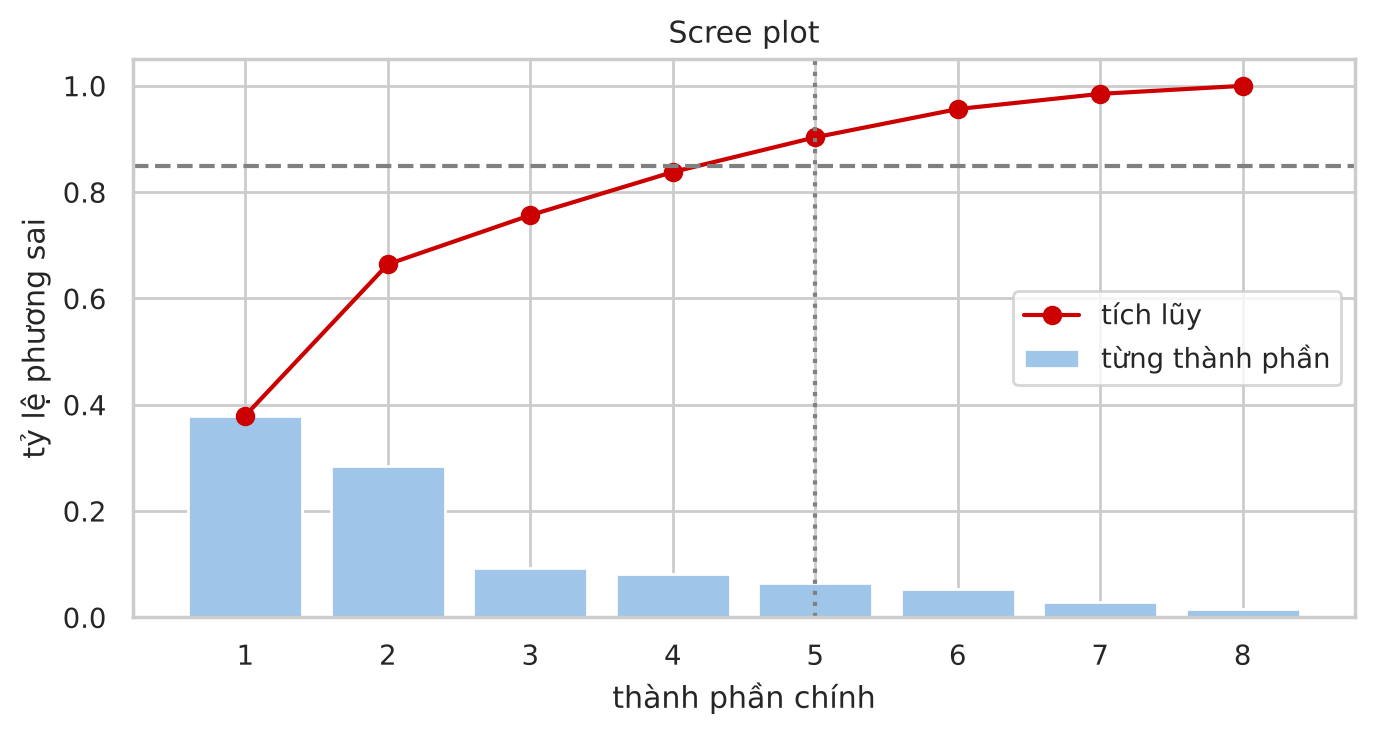

,PC1,PC2,PC3,PC4,PC5
age,0.41,0.06,0.14,0.64,-0.47
log_tenure_months,0.22,0.47,0.06,0.43,0.54
log_annual_income,0.50,0.08,0.15,-0.40,0.20
log_orders_per_year,0.02,0.61,-0.11,-0.02,0.04
log_avg_order_value,0.51,-0.01,0.22,-0.36,0.09
log_days_since_last_purchase,0.00,-0.54,0.20,0.32,0.59
return_rate,-0.31,0.17,0.92,-0.05,-0.12
discount_usage_rate,-0.41,0.28,-0.09,-0.03,0.26


In [6]:
pca_full = PCA().fit(Xs)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_pc = int(np.argmax(cum >= 0.85) + 1)
print("Phuong sai giai thich:", pca_full.explained_variance_ratio_.round(3))
print("Tich luy:", cum.round(3), f"-> chon {n_pc} thanh phan ({cum[n_pc - 1]:.1%})")
fig, ax = plt.subplots(figsize=(7, 3.8))
k_ = np.arange(1, len(cum) + 1)
ax.bar(k_, pca_full.explained_variance_ratio_, color="#9fc5e8", label="từng thành phần")
ax.plot(k_, cum, "o-", color="#cc0000", label="tích lũy"); ax.axhline(0.85, ls="--", color="gray")
ax.axvline(n_pc, ls=":", color="gray"); ax.set_xlabel("thành phần chính"); ax.set_ylabel("tỷ lệ phương sai")
ax.set_title("Scree plot"); ax.legend(); fig.tight_layout(); fig.savefig(OUT_FIG / "d_pca_variance.png", dpi=150); plt.show()
pca = PCA(n_components=n_pc, random_state=SEED).fit(Xs)
Cp = pd.DataFrame(pca.transform(Xs), columns=[f"PC{i + 1}" for i in range(n_pc)], index=df.index)
pd.DataFrame(pca.components_.T, index=NUM_FEATS, columns=Cp.columns).round(2)

**Nhận xét D5.** Hai thành phần đầu giải thích 66,4% phương sai; 5 thành phần đạt 90,3% (4 thành phần chỉ 83,8%, chưa tới ngưỡng 85%). Diễn giải theo hệ số tải:

- **PC1 (38,0%) – mức giàu có và giá trị đơn:** income (0,50), AOV (0,51), age (0,41) cùng dấu; discount (−0,41) và return_rate (−0,31) ngược dấu. Khách thu nhập cao, đơn giá trị lớn, ít săn khuyến mãi.
- **PC2 (28,5%) – mức độ gắn kết:** orders (0,61), tenure (0,47) dương; recency (−0,54) âm. Khách mua thường xuyên, gắn bó lâu, mua gần đây.
- **PC3 (9,2%)** gần như chỉ là return_rate (0,92).
- PC4, PC5 chủ yếu là tuổi và tenure.

Hai trục đầu trùng với hai chiều nghiệp vụ quen thuộc (Monetary; Frequency/Recency), nên PCA ở đây vẫn diễn giải được. 3 thành phần bị bỏ chiếm 9,7% phương sai.

## D6. Chọn phương án cuối

| Phương án | Không gian đặc trưng |
|---|---|
| A | Thuộc tính số (log + chuẩn hóa) + gender + region + preferred_category (one-hot) |
| B | Như A nhưng bỏ preferred_category |
| C | PCA của các thuộc tính số (log + chuẩn hóa) |

Tiêu chí nhanh: silhouette của K-Means với k = 2..8 (`n_init = 10`, seed cố định), kèm độ ổn định trên 3 mẫu bootstrap (ARI giữa nhãn của mô hình huấn luyện trên mẫu bootstrap và nhãn của mô hình gốc). Lưu ý: silhouette đo trong các không gian khác nhau không so sánh được tuyệt đối, nên chỉ dùng để chọn nhanh; quy tắc: chỉ chọn PCA nếu tốt hơn rõ rệt, nếu không ưu tiên không gian dễ giải thích.

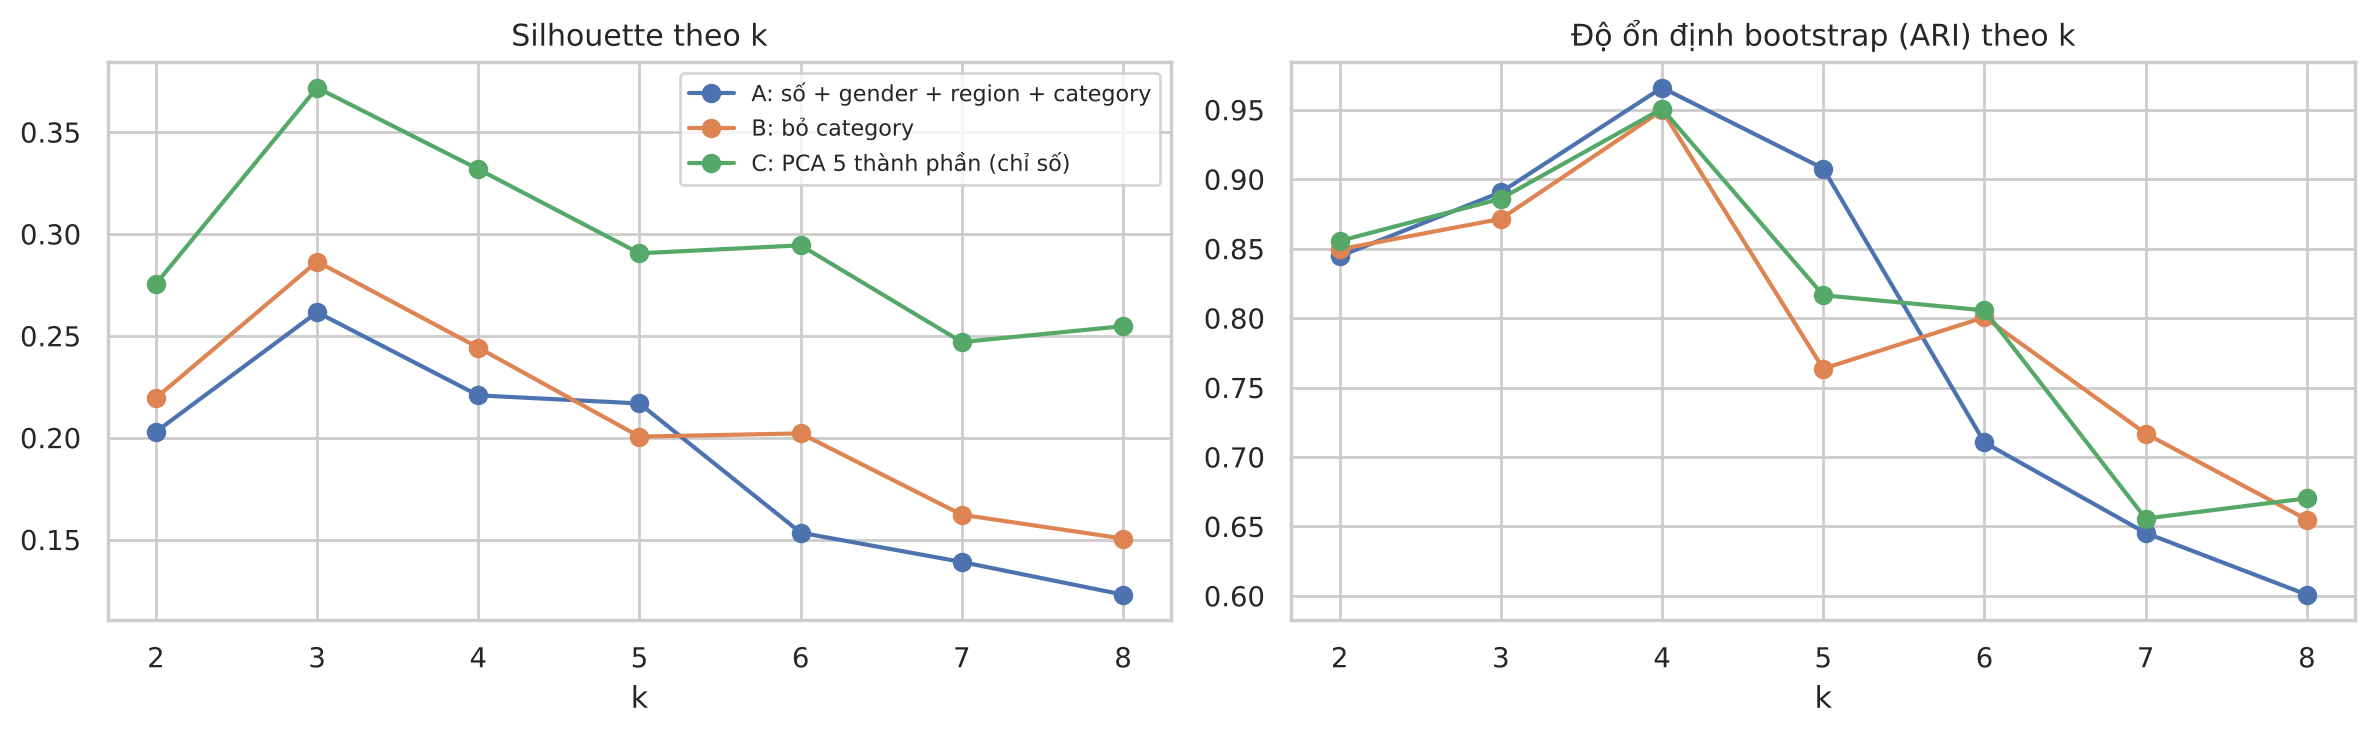

phuong_an,A: số + gender + region + category,B: bỏ category,C: PCA 5 thành phần (chỉ số)
k,,,
2,0.203,0.220,0.275
3,0.262,0.286,0.372
4,0.221,0.244,0.332
5,0.217,0.201,0.291
6,0.153,0.202,0.294
7,0.139,0.162,0.247
8,0.123,0.151,0.255


In [7]:
OPTIONS = {"A: số + gender + region + category": A, "B: bỏ category": B, f"C: PCA {n_pc} thành phần (chỉ số)": Cp}
KS = range(2, 9); rng = np.random.default_rng(SEED)
boots = [rng.choice(len(df), len(df), replace=True) for _ in range(3)]
rows = []
for name, M in OPTIONS.items():
    V = M.to_numpy(float)
    for k in KS:
        km = KMeans(k, n_init=10, random_state=SEED).fit(V)
        ari = np.mean([adjusted_rand_score(km.labels_, KMeans(k, n_init=10, random_state=SEED).fit(V[b]).predict(V)) for b in boots])
        rows.append({"phuong_an": name, "so_cot": V.shape[1], "k": k, "silhouette": silhouette_score(V, km.labels_),
                     "on_dinh_ARI": ari, "cum_nho_nhat": np.bincount(km.labels_).min()})
res = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, g in res.groupby("phuong_an"):
    axes[0].plot(g.k, g.silhouette, "o-", label=name); axes[1].plot(g.k, g.on_dinh_ARI, "o-", label=name)
axes[0].set_title("Silhouette theo k"); axes[1].set_title("Độ ổn định bootstrap (ARI) theo k")
for ax in axes: ax.set_xlabel("k")
axes[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(OUT_FIG / "d_silhouette_k.png", dpi=150); plt.show()
res.pivot(index="k", columns="phuong_an", values="silhouette").round(3)

In [8]:
# Tom tat: xet k >= 3 (k = 2 chi tach hai khoi lon, khong dap ung muc tieu 3-6 cum da dat o cau a)
sel = res[res.k.between(3, 6)]
choice = sel.loc[sel.groupby("phuong_an").silhouette.idxmax()].set_index("phuong_an")
choice["silhouette_TB_k3-6"] = sel.groupby("phuong_an").silhouette.mean()
choice["on_dinh_TB_k3-6"] = sel.groupby("phuong_an").on_dinh_ARI.mean()
choice = choice.rename(columns={"k": "k_tot_nhat", "silhouette": "silhouette_max"})
choice.round(3)

,so_cot,k_tot_nhat,silhouette_max,on_dinh_ARI,cum_nho_nhat,silhouette_TB_k3-6,on_dinh_TB_k3-6
phuong_an,,,,,,,
A: số + gender + region + category,17,3,0.262,0.891,60,0.213,0.869
B: bỏ category,12,3,0.286,0.871,59,0.233,0.846
C: PCA 5 thành phần (chỉ số),5,3,0.372,0.886,60,0.322,0.865


In [9]:
# Kiem tra bo sung (khong phai phuong an thu tu): chi cac thuoc tinh so da chuan hoa, khong PCA
V = Xs.to_numpy()
num_only = pd.DataFrame([{"k": k, "silhouette": silhouette_score(V, KMeans(k, n_init=10, random_state=SEED).fit_predict(V))}
                         for k in range(3, 7)]).set_index("k").T
print("Chi thuoc tinh so da chuan hoa (khong gender/region/category, khong PCA):"); print(num_only.round(3))

Chi thuoc tinh so da chuan hoa (khong gender/region/category, khong PCA):
k               3      4      5      6
silhouette  0.327  0.287  0.242  0.245


**Nhận xét D6.**

- **Theo silhouette, thêm thuộc tính danh mục làm giảm chất lượng cụm** (câu e kiểm chứng bằng nhãn thật: ARI gần như không đổi, 0,885 so với 0,889 ở k = 4, nên việc loại chúng là *vô hại và làm mô hình gọn hơn*, chứ không phải cải thiện cấu trúc cụm). Silhouette trung bình (k = 3..6): A = 0,213; B (bỏ category) = 0,233; chỉ thuộc tính số = 0,275; PCA = 0,322. Mỗi lần bỏ một nhóm thuộc tính danh mục, silhouette đều tăng. Điều này khớp với câu b: gender, region không liên hệ với thuộc tính nào, nên chỉ thêm các chiều nhiễu vào khoảng cách. **`preferred_category`, `gender`, `region` bị loại khỏi không gian phân cụm, nhưng được giữ để mô tả cụm ở câu e.** Đây cũng là kết quả của phép thử với `gender` đặt ra ở câu a.
- **PCA cải thiện so với không gian số đầy đủ** ở mọi k (k = 3: 0,372 so với 0,327; trung bình 0,322 so với 0,275, chênh 0,047, vượt ngưỡng 0,02 đã đặt). Độ ổn định bootstrap của ba phương án tương đương (0,85–0,87), nên không phân định được bằng tiêu chí này.
- Cả ba phương án đều cho silhouette cao nhất tại k = 3, với cụm nhỏ nhất khoảng 60 khách.

**Hạn chế cần nêu:** silhouette có xu hướng tăng khi giảm số chiều, vì các chiều ít cấu trúc bị loại, nên mức cải thiện của PCA một phần là hiệu ứng của thước đo chứ không hoàn toàn là cụm tốt hơn. Chỉ 3 mẫu bootstrap nên độ ổn định chỉ mang tính tham khảo. Việc PCA có thật sự giúp tìm đúng cấu trúc hay không sẽ được kiểm tra ở câu e bằng nhãn `true_segment`; không gian số đầy đủ cũng được lưu lại (`customers_scaled_numeric.csv`) để đối chiếu.

## D7. Lưu dữ liệu đã chuẩn bị

In [10]:
# Quy tac chon: lay phuong an co silhouette trung binh (k = 3..6) cao nhat; PCA chi duoc chon neu hon
# khong gian thuoc tinh so day du it nhat 0,02, neu khong thi giu khong gian day du de de giai thich.
names = list(OPTIONS)
best = choice["silhouette_TB_k3-6"].idxmax()
num_mean = float(num_only.loc["silhouette"].mean())
if best == names[2] and choice.loc[best, "silhouette_TB_k3-6"] - num_mean < 0.02:
    final, final_name = Xs.copy(), "Thuộc tính số đã log + StandardScaler (không PCA)"
elif best == names[2]:
    final, final_name = Cp.copy(), names[2]
else:
    final, final_name = OPTIONS[best].copy(), best
choice["duoc_chon"] = [n == final_name for n in choice.index]
choice.loc["Chỉ thuộc tính số, không PCA (kiểm tra bổ sung)", ["so_cot", "silhouette_TB_k3-6", "duoc_chon"]] = \
    [Xs.shape[1], num_mean, final_name.startswith("Thuộc tính số")]
choice.to_csv(OUT_TAB / "d_model_choice.csv", encoding="utf-8-sig")

prepared = pd.concat([df[[ID_COL]], final], axis=1)
prepared.to_csv(PROCESSED / "customers_prepared.csv", index=False, encoding="utf-8-sig")
# khong gian thuoc tinh so day du va cac cot mo ta: de cau e dung khi mo ta cum
pd.concat([df[[ID_COL]], Xs], axis=1).to_csv(PROCESSED / "customers_scaled_numeric.csv", index=False, encoding="utf-8-sig")

summary = pd.DataFrame([
    ("1", "log1p", ", ".join(LOGC), f"|skew| lớn nhất: {skew.skew_truoc.abs().max():.1f} -> {skew.skew_sau.abs().max():.1f}"),
    ("2", "Bỏ thuộc tính", "membership_tier" + (", sessions_per_month" if drop_sessions else ""),
     f"Spearman tier~chi tiêu {r_tier:.2f}; sessions~orders {r_sess:.2f}"),
    ("3", "Mã hóa", "gender 0/1; region, preferred_category one-hot", f"{1 + region.shape[1] + category.shape[1]} cột nhị phân"),
    ("4", "StandardScaler", ", ".join(NUM_FEATS), "mean 0, std 1 cho mọi thuộc tính số"),
    ("5", "PCA (để so sánh)", f"{n_pc} thành phần", f"{cum[n_pc - 1]:.1%} phương sai"),
    ("6", "Phương án cuối", final_name, f"{prepared.shape[0]} dòng × {final.shape[1]} đặc trưng (+ customer_id)"),
], columns=["buoc", "thao_tac", "ap_dung_cho", "ket_qua"])
summary.to_csv(OUT_TAB / "d_pipeline_summary.csv", index=False, encoding="utf-8-sig")
print("PHUONG AN CUOI:", final_name)
print(f"customers_prepared.csv: {prepared.shape[0]} dong x {prepared.shape[1]} cot ({final.shape[1]} dac trung + customer_id)")
print("Dac trung:", list(final.columns))
assert prepared.shape[0] == 220 and prepared.isna().sum().sum() == 0
summary

PHUONG AN CUOI: C: PCA 5 thành phần (chỉ số)
customers_prepared.csv: 220 dong x 6 cot (5 dac trung + customer_id)
Dac trung: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']


,buoc,thao_tac,ap_dung_cho,ket_qua
0,1,log1p,"annual_income, avg_order_value, orders_per_yea...",|skew| lớn nhất: 8.1 -> 1.9
1,2,Bỏ thuộc tính,"membership_tier, sessions_per_month",Spearman tier~chi tiêu 0.88; sessions~orders 0.90
2,3,Mã hóa,"gender 0/1; region, preferred_category one-hot",9 cột nhị phân
3,4,StandardScaler,"age, log_tenure_months, log_annual_income, log...","mean 0, std 1 cho mọi thuộc tính số"
4,5,PCA (để so sánh),5 thành phần,90.3% phương sai
5,6,Phương án cuối,C: PCA 5 thành phần (chỉ số),220 dòng × 5 đặc trưng (+ customer_id)


## Tóm tắt câu d

| Câu hỏi | Trả lời |
|---|---|
| Vì sao log1p? | Nén đuôi phải để cực trị hợp lý không chi phối khoảng cách Euclid, mà không xóa khách giá trị cao; |skew| lớn nhất 8,1 → 1,9 |
| Vì sao bỏ membership_tier, sessions? | Trùng thông tin (Spearman 0,88 và 0,90), làm một khía cạnh bị tính hai lần |
| Vì sao không Gower/K-Medoids? | K-Means cần không gian Euclid; thuộc tính danh mục ở đây không mang cấu trúc cụm nên thước đo hỗn hợp ít lợi ích, lại làm phức tạp so sánh ở câu e |
| Vì sao StandardScaler? | Sau log không còn cực trị nặng; cho mọi thuộc tính cùng trọng số, RobustScaler thì không (std lệch nhau 1,77 lần) |
| Vì sao PCA 5 thành phần? | 90,3% phương sai; silhouette cao hơn không gian đầy đủ ở mọi k (trung bình 0,322 so với 0,275); hai trục đầu diễn giải được. Câu e cho thấy mức tăng này chủ yếu do giảm số chiều: ARI bằng nhau ở k = 3 |
| Có dùng true_segment không? | Không. File đầu vào không chứa cột này; mọi lựa chọn dựa trên Spearman, phương sai, silhouette và bootstrap |

**Sự thay đổi của dữ liệu:** 13 thuộc tính hỗn hợp trên thang gốc (độ lệch chuẩn chênh nhau gần 48.000 lần) → 8 thuộc tính số đã log và chuẩn hóa → **5 thành phần chính**. Số dòng giữ nguyên **220** (không giảm số đối tượng: N nhỏ, lấy mẫu sẽ làm nhóm ít khách thiếu đại diện).

**Sản phẩm:** `data/processed/customers_prepared.csv`: **220 dòng × 6 cột** (`customer_id` + PC1..PC5).